# 05 – Evaluation

**Step 3 of the implementation plan.** All results use the **test set** (80% of candidates, never used for tuning).

1. **Main result:** generic vs local-aware mode – NDCG@k, precision@k, recall@k, with 95% confidence intervals and a significance test.
2. **By scenario:** exact / equivalent / under-qualified candidates.
3. **Sensitivity:** family-only relevance (`rel_occupation`), and different location penalties and credential floors.
4. **Fairness:** recommendation quality by gender, age, education level and home district; exposure of job districts.
5. **Mitigation:** eligibility-first re-ranking, before vs after.
6. **Training pathways:** can each candidate close the credential gaps for their top-3 jobs with local, affordable, time-feasible training?

Figures go to `figures/`, tables to `results/`.

In [11]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.limpopo import read_csv_any_encoding, LocalVocab, ndcg_at_k, precision_at_k, recall_at_k

LOCAL, PROCESSED = ROOT / "data" / "raw" / "local", ROOT / "data" / "processed"
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

z = np.load(PROCESSED / "match_scores.npz", allow_pickle=True)
REL, REL_OCC = z["rel"], z["rel_occupation"]
cfg = json.load(open(PROCESSED / "matcher_config.json"))
cands = pd.read_csv(PROCESSED / "candidates.csv", dtype=str).fillna("").merge(
        pd.read_csv(PROCESSED / "candidate_split.csv", dtype=str), on="candidate_id")
assert list(cands["candidate_id"]) == list(z["candidate_ids"]), "candidate order mismatch – re-run notebook 04"
jobs = pd.read_csv(PROCESSED / "job_requirements.csv", dtype=str).fillna("")
assert list(jobs["job_id"]) == list(z["job_ids"]), "job order mismatch – re-run notebook 04"
lv = LocalVocab(read_csv_any_encoding(LOCAL / "local_vocabulary.csv"), read_csv_any_encoding(LOCAL / "equivalences.csv"))

TEST = np.where(cands["split"] == "test")[0]
print(f"Test candidates: {len(TEST)} | semantic method: {cfg['semantic_method']} | tuned w: {cfg['best_w']}")

Test candidates: 480 | semantic method: sentence-transformers/all-MiniLM-L6-v2 | tuned w: {'generic': 0.25, 'local': 0.25}


## 1. Main result

In [12]:
KS = [5, 10]

def per_candidate(S, rel, rows, threshold=2):
    out = []
    for i in rows:
        order = np.argsort(-S[i], kind="stable")
        r = rel[i, order]
        row = {"i": i}
        for k in KS:
            row[f"NDCG@{k}"] = ndcg_at_k(r, rel[i], k)
            row[f"P@{k}"] = precision_at_k(r, k, threshold)
        row["R@10"] = recall_at_k(r, rel[i], 10, threshold)
        out.append(row)
    return pd.DataFrame(out).set_index("i")

SCORES = {"generic": z["generic"], "local": z["local"]}
pc = {m: per_candidate(S, REL, TEST) for m, S in SCORES.items()}
pc_occ = {m: per_candidate(S, REL_OCC, TEST, threshold=1) for m, S in SCORES.items()}

def compare(pcd, label, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); rows = []
    for metric in pcd["generic"].columns:
        g, l = pcd["generic"][metric], pcd["local"][metric]
        d = (l - g).dropna()
        boots = [rng.choice(d.values, size=len(d), replace=True).mean() for _ in range(n_boot)]
        p = stats.wilcoxon(d.values).pvalue if (d != 0).any() else 1.0
        rows.append({"relevance": label, "metric": metric, "generic": g.mean(), "local": l.mean(),
                     "difference": d.mean(), "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5),
                     "wilcoxon_p": p, "n": len(d)})
    return pd.DataFrame(rows)

main = pd.concat([compare(pc, "full (family + eligible + reachable)"), compare(pc_occ, "family only")])
main.to_csv(RES / "05_main_results.csv", index=False)
main.round(3)

,relevance,metric,generic,local,difference,ci_low,ci_high,wilcoxon_p,n
0,full (family + eligible + reachable),NDCG@5,0.231,0.355,0.124,0.096,0.150,0.000,480
1,full (family + eligible + reachable),P@5,0.122,0.255,0.132,0.112,0.152,0.000,480
2,full (family + eligible + reachable),NDCG@10,0.243,0.348,0.106,0.081,0.131,0.000,480
3,full (family + eligible + reachable),P@10,0.104,0.193,0.089,0.074,0.103,0.000,480
4,full (family + eligible + reachable),R@10,0.221,0.489,0.268,0.232,0.306,0.000,386
0,family only,NDCG@5,0.300,0.335,0.035,0.007,0.062,0.009,480
1,family only,P@5,0.279,0.309,0.030,0.003,0.055,0.039,480
2,family only,NDCG@10,0.293,0.314,0.022,-0.001,0.047,0.080,480
3,family only,P@10,0.245,0.248,0.003,-0.016,0.024,0.799,480
4,family only,R@10,0.161,0.185,0.024,0.006,0.041,0.034,480


**How to read this:** *difference* = local − generic (positive favours local-aware mode). If the 95% CI excludes 0 and the Wilcoxon p-value is below 0.05, the difference is statistically significant. NDCG uses graded relevance (2/1/0); precision and recall count only fully relevant jobs (rel = 2) for the full ground truth, and same-family jobs for family-only.

## 2. Results by candidate scenario

In [13]:
scen = cands.loc[TEST, "scenario"]
by_scen = pd.concat({m: pc[m].join(scen.rename("scenario")).groupby("scenario")[["NDCG@10", "P@10"]].mean()
                     for m in pc}, axis=1).round(3)
by_scen.to_csv(RES / "05_by_scenario.csv")
by_scen

generic          local       
           NDCG@10   P@10 NDCG@10   P@10
scenario                                
equivalent   0.255  0.135   0.313  0.187
exact        0.250  0.126   0.413  0.249
under        0.221  0.044   0.265  0.104

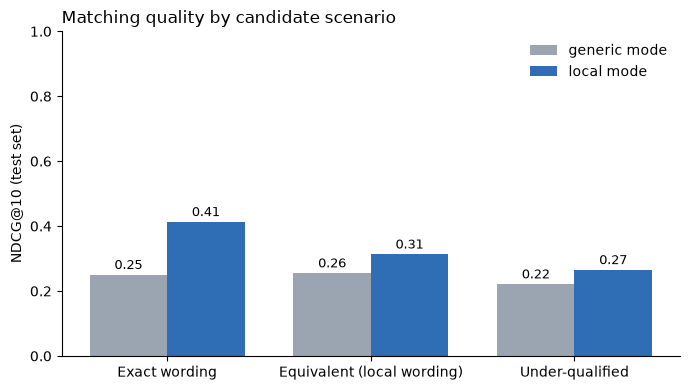

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["exact", "equivalent", "under"]
x = np.arange(len(order)); wbar = 0.38
for k, (mode, colr) in enumerate([("generic", "#9AA5B1"), ("local", "#2F6DB5")]):
    vals = [by_scen.loc[s, (mode, "NDCG@10")] if s in by_scen.index else np.nan for s in order]
    bars = ax.bar(x + (k - 0.5) * wbar, vals, wbar, label=f"{mode} mode", color=colr)
    ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_xticks(x, ["Exact wording", "Equivalent (local wording)", "Under-qualified"])
ax.set_ylabel("NDCG@10 (test set)"); ax.set_ylim(0, 1)
ax.set_title("Matching quality by candidate scenario", loc="left")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "05_ndcg_by_scenario.png", dpi=200); plt.show()

## 3. Sensitivity: location penalty and credential floor

Local-aware scores are recomputed from the saved components with different settings (the tuned `w` is kept). A penalty of 1.0 means location is ignored; a floor of 1.0 means credentials are ignored. This shows which local component drives the result, and the trade-off with family-only relevance.

In [15]:
w = cfg["best_w"]["local"]
base = w * z["semantic"] + (1 - w) * z["overlap_local"]
rows = []  
for pen in [0.25, 0.5, 0.75, 1.0]:
    for floor in [0.25, 0.5, 0.75, 1.0]:
        S = base * (floor + (1 - floor) * z["credential_fit"]) * np.where(z["reachable"], 1.0, pen)
        rows.append({"location_penalty": pen, "credential_floor": floor,
                     "NDCG@10 full": per_candidate(S, REL, TEST)["NDCG@10"].mean(),
                     "NDCG@10 family-only": per_candidate(S, REL_OCC, TEST, 1)["NDCG@10"].mean()})
sens = pd.DataFrame(rows)
sens.to_csv(RES / "05_sensitivity.csv", index=False)
print("Generic mode for reference – full:", round(pc["generic"]["NDCG@10"].mean(), 3),
      "| family-only:", round(pc_occ["generic"]["NDCG@10"].mean(), 3))
sens.pivot(index="location_penalty", columns="credential_floor", values="NDCG@10 full").round(3)

Generic mode for reference – full: 0.243 | family-only: 0.293


credential_floor,0.25,0.50,0.75,1.00
location_penalty,,,,
0.25,0.350,0.344,0.327,0.285
0.50,0.355,0.348,0.327,0.285
0.75,0.366,0.364,0.342,0.295
1.00,0.365,0.370,0.361,0.318


In [16]:
sens.pivot(index="location_penalty", columns="credential_floor", values="NDCG@10 family-only").round(3)

credential_floor,0.25,0.50,0.75,1.00
location_penalty,,,,
0.25,0.305,0.306,0.307,0.296
0.50,0.312,0.314,0.308,0.296
0.75,0.331,0.338,0.330,0.308
1.00,0.371,0.384,0.389,0.366


## 4. Fairness

**Candidate side:** is recommendation quality (NDCG@10, full ground truth) similar across groups? We report each group's mean and the gap between the best and worst group (difference) and their ratio (worst ÷ best; 1.0 = equal).
Group attributes were assigned at random in notebook 03 (gender, age) or follow from qualifications (education) and home (district), so gaps come from the matcher's behaviour, not from the data generation.

In [17]:
GROUPS = ["gender", "age_band", "education_level", "home_district"]

def group_table(pcd, metric="NDCG@10"):
    rows = []
    for g in GROUPS:
        attr = cands.loc[TEST, g]
        for mode in pcd:
            means = pcd[mode][metric].groupby(attr).mean()
            rows.append({"attribute": g, "mode": mode, **{f"{k}": round(v, 3) for k, v in means.items()},
                         "difference": round(means.max() - means.min(), 3),
                         "ratio": round(means.min() / means.max(), 3) if means.max() > 0 else np.nan})
    return pd.DataFrame(rows)

try:
    from fairlearn.metrics import MetricFrame
    mf = MetricFrame(metrics=lambda y_true, y_pred: float(np.nanmean(y_true)),
                     y_true=pc["local"]["NDCG@10"].values, y_pred=pc["local"]["NDCG@10"].values,
                     sensitive_features=cands.loc[TEST, "education_level"].values)
    print("fairlearn check (local mode, education level) – difference:", round(mf.difference(), 3),
          "ratio:", round(mf.ratio(), 3))
except ImportError:
    print("fairlearn not installed – using pandas (same numbers). pip install fairlearn to add the check.")

fair = group_table(pc)
fair.to_csv(RES / "05_fairness_by_group.csv", index=False)
fair[["attribute", "mode", "difference", "ratio"]]

fairlearn check (local mode, education level) – difference: 0.182 ratio: 0.633


,attribute,mode,difference,ratio
0,gender,generic,0.001,0.995
1,gender,local,0.019,0.947
2,age_band,generic,0.021,0.916
3,age_band,local,0.058,0.842
4,education_level,generic,0.141,0.537
5,education_level,local,0.182,0.633
6,home_district,generic,0.088,0.689
7,home_district,local,0.111,0.719


In [18]:
for g in GROUPS:
    print(f"\n{g}:")
    print(fair[fair["attribute"] == g].drop(columns=["attribute"]).dropna(axis=1, how="all").set_index("mode").to_string())


gender:
         Female   Male  difference  ratio
mode                                     
generic   0.243  0.242       0.001  0.995
local     0.339  0.358       0.019  0.947

age_band:
         difference  ratio  18-24  25-34  35-44  45-59
mode                                                  
generic       0.021  0.916  0.254  0.240  0.240  0.233
local         0.058  0.842  0.311  0.358  0.369  0.363

education_level:
         difference  ratio  Below matric  Degree or higher  Diploma  Matric / NC(V) L4  TVET or trade
mode                                                                                                 
generic       0.141  0.537         0.163             0.303    0.249              0.212          0.231
local         0.182  0.633         0.495             0.327    0.313              0.340          0.471

home_district:
         difference  ratio  Capricorn  Mopani  Sekhukhune  Vhembe  Waterberg
mode                                                                     

**Job side (exposure):** share of top-10 recommendation slots going to jobs in each district, compared with that district's share of all jobs.

In [19]:
JOB_DIST = jobs["district"].to_numpy()
exp_rows = {}
for mode, S in SCORES.items():
    top = np.argsort(-S[TEST], axis=1, kind="stable")[:, :10]
    exp_rows[f"{mode} top-10 share"] = pd.Series(JOB_DIST[top.ravel()]).value_counts(normalize=True)
exposure = pd.DataFrame(exp_rows)
exposure["share of all jobs"] = pd.Series(JOB_DIST).value_counts(normalize=True)
exposure = exposure.fillna(0).round(3).sort_values("share of all jobs", ascending=False)
exposure.to_csv(RES / "05_district_exposure.csv")
exposure

,generic top-10 share,local top-10 share,share of all jobs
Capricorn,0.457,0.458,0.471
Sekhukhune,0.189,0.182,0.162
Waterberg,0.149,0.134,0.129
Vhembe,0.107,0.117,0.122
Mopani,0.098,0.108,0.094
Unknown,0.001,0.001,0.023


## 5. Mitigation: eligibility-first re-ranking

A simple post-processing step on local-aware mode: within each candidate's top 20, jobs the matcher believes the candidate fully qualifies for (credential fit = 1) move ahead of the others, keeping score order within each group. Goal: fewer recommendations the candidate cannot apply for, especially for candidates with lower qualifications.

In [20]:
def eligibility_first(S, fit, top_n=20):
    S2 = S.copy()
    for i in range(S.shape[0]):
        order = np.argsort(-S[i], kind="stable")[:top_n]
        boost = (fit[i, order] >= 1.0).astype(float)
        S2[i, order] = S[i, order] + 10 * boost            # moves fully-qualified jobs to the front of the top 20
    return S2

S_mit = eligibility_first(z["local"], z["credential_fit"])
pc["local + re-ranking"] = per_candidate(S_mit, REL, TEST)
pc_occ["local + re-ranking"] = per_candidate(S_mit, REL_OCC, TEST, 1)

summary = pd.DataFrame({m: pc[m][["NDCG@10", "P@10"]].mean() for m in pc}).T.round(3)
fair_mit = group_table(pc)
mit_gap = fair_mit.pivot(index="attribute", columns="mode", values="difference")
fair_mit.to_csv(RES / "05_fairness_with_mitigation.csv", index=False)
print("Overall (full ground truth):"); print(summary.to_string())
print("\nBest–worst group gap in NDCG@10 (smaller = fairer):"); print(mit_gap.round(3).to_string())

Overall (full ground truth):
                    NDCG@10   P@10
generic               0.243  0.104
local                 0.348  0.193
local + re-ranking    0.343  0.202

Best–worst group gap in NDCG@10 (smaller = fairer):
mode             generic  local  local + re-ranking
attribute                                          
age_band           0.021  0.058               0.077
education_level    0.141  0.182               0.170
gender             0.001  0.019               0.029
home_district      0.088  0.111               0.085


## 6. Training pathways

For each test candidate's **top-3 local-aware recommendations**, every missing mandatory credential (from notebook 04) is matched to options in `training_options.csv`. An option is **feasible** if it:
- addresses the missing credential (directly or through an equivalence rule);
- is offered in a district the candidate can reach, or province-wide/distance;
- costs no more than the candidate's training budget (R0 options assume NSFAS or free provision);
- fits the candidate's weekly hours (not checked for courses under one month);
- has entry requirements the candidate meets;
- is open to job seekers (not employer-provided or after-appointment only).

A recommendation's gap is **closable** if every missing requirement has at least one feasible option.

In [21]:
train = read_csv_any_encoding(LOCAL / "training_options.csv")
train["addresses_set"] = train["addresses"].map(lambda s: set(filter(None, s.split(";"))))
train["entry_set"] = train["entry_requirements"].map(lambda s: set(filter(None, s.split(";"))))
for c in ["duration_months", "hours_per_week", "cost_rand"]:
    train[c] = pd.to_numeric(train[c])

gaps = pd.read_csv(PROCESSED / "skills_gap.csv", dtype=str).fillna("")
gaps = gaps[gaps["candidate_id"].isin(cands.loc[TEST, "candidate_id"])]
C = cands.set_index("candidate_id")

def option_status(opt, cand, have):
    if opt["availability"] in ("employer_provided", "after_appointment"):
        return "not open to job seekers"
    reach = set(cand["reachable_districts"].split(";"))
    if opt["districts"] != "ALL" and not (set(opt["districts"].split(";")) & reach):
        return "not offered nearby"
    if opt["entry_set"] and not all(e in have for e in opt["entry_set"]):
        return "entry requirement not met"
    if opt["cost_rand"] > float(cand["train_budget_rand"]):
        return "too expensive"
    if opt["duration_months"] >= 1 and opt["hours_per_week"] > float(cand["train_hours_week"]):
        return "not enough time per week"
    return "feasible"

rows = []
for _, g in gaps.iterrows():
    cand = C.loc[g["candidate_id"]]
    held = set(cand["credentials"].split(";"))
    have = lv.closure(held, verified_only=False)
    missing = json.loads(g["missing_credential_ids"])
    if not missing:
        rows.append({**g, "status": "no credential gap", "months_needed": 0, "options": ""}); continue
    group_ok, months, chosen, reasons = True, 0.0, [], []
    for grp in missing:
        cands_opts = train[train["addresses_set"].map(
            lambda a: bool(a & set(grp)) or any(r in lv.closure(a, verified_only=False) for r in grp))]
        if cands_opts.empty:
            group_ok = False; reasons.append("no training option listed"); continue
        st = cands_opts.apply(lambda o: option_status(o, cand, have), axis=1)
        feas = cands_opts[st == "feasible"]
        if feas.empty:
            group_ok = False; reasons.append(st.value_counts().index[0]); continue
        best = feas.sort_values(["duration_months", "cost_rand"]).iloc[0]
        months = max(months, best["duration_months"]); chosen.append(best["option_id"])
    rows.append({**g, "status": "closable" if group_ok else "blocked: " + "; ".join(sorted(set(reasons))),
                 "months_needed": months if group_ok else np.nan, "options": ";".join(chosen)})
path = pd.DataFrame(rows)
path["closable_within_6_months"] = path["months_needed"] <= 6

n = len(path)
print(f"Top-3 recommendations evaluated: {n}")
print(f"  No credential gap:              {(path['status'] == 'no credential gap').mean():.0%}")
print(f"  Gap closable with local training:{(path['status'] == 'closable').mean():.0%}")
print(f"     ... of which within 6 months: {(path['closable_within_6_months'] & (path['status'] == 'closable')).sum() / max(1, (path['status'] == 'closable').sum()):.0%}")
print(f"  Gap blocked:                    {path['status'].str.startswith('blocked').mean():.0%}")
print("\nMain reasons a gap is blocked:")
print(path.loc[path["status"].str.startswith("blocked"), "status"].str.replace("blocked: ", "").str.split("; ").explode().value_counts().to_string())
path.to_csv(RES / "05_training_pathways.csv", index=False)

Top-3 recommendations evaluated: 1440
  No credential gap:              91%
  Gap closable with local training:1%
     ... of which within 6 months: 90%
  Gap blocked:                    8%

Main reasons a gap is blocked:
status
too expensive                49
not enough time per week     30
not open to job seekers      18
not offered nearby           14
no training option listed    12
entry requirement not met     5


In [22]:
# Pathway feasibility by group (share of top-3 recommendations that are already met or closable)
path["usable"] = path["status"].isin(["no credential gap", "closable"])
path = path.join(C[["education_level", "home_district", "train_budget_rand"]], on="candidate_id")
pd.concat({g: path.groupby(g)["usable"].mean().round(2) for g in ["education_level", "home_district", "train_budget_rand"]})

education_level    Below matric         0.92
                   Degree or higher     0.94
                   Diploma              0.99
                   Matric / NC(V) L4    0.82
                   TVET or trade        0.94
home_district      Capricorn            0.93
                   Mopani               0.94
                   Sekhukhune           0.95
                   Vhembe               0.85
                   Waterberg            0.91
train_budget_rand  0                    0.95
                   15000                0.95
                   2000                 0.89
                   500                  0.90
                   5000                 0.93
Name: usable, dtype: float64

In [23]:
# Worked pathway example for the write-up
ex = path[path["status"] == "closable"].sort_values("months_needed").iloc[0]
cand = C.loc[ex["candidate_id"]]
print("Candidate:", cand["profile_text"][:220], "...\n")
print("Recommended job:", jobs.set_index("job_id").loc[ex["job_id"], "title"])
print("Missing:", ex["missing_credentials"])
for oid in ex["options"].split(";"):
    o = train.set_index("option_id").loc[oid]
    print(f"  -> {o['name']} | {o['provider']} | {o['duration_months']} months | R{o['cost_rand']:.0f} | {o['funding']}")

Candidate: Job seeker from Hoedspruit, Mopani District. Qualifications: Bachelor's degree in Child and Youth Care; SACSSP registration (social work). Experience: 14 years as rehabilitation support worker. Skills: maintain records o ...

Recommended job: Social Worker Grade 1
Missing: Valid driver's licence (any code)
  -> Driving lessons + learner's and driving test (Code B / old Code 08) | Driving school + DLTC | 2.0 months | R5000 | self


## 7. Key numbers for the write-up

In [24]:
m = main.set_index(["relevance", "metric"])
full = "full (family + eligible + reachable)"
def line(rel, metric):
    r = m.loc[(rel, metric)]
    sig = "significant" if (r["ci_low"] > 0 or r["ci_high"] < 0) and r["wilcoxon_p"] < 0.05 else "not significant"
    return (f"{metric}: generic {r['generic']:.3f} vs local {r['local']:.3f} "
            f"(difference {r['difference']:+.3f}, 95% CI {r['ci_low']:+.3f} to {r['ci_high']:+.3f}, p = {r['wilcoxon_p']:.3g}, {sig})")
print("Semantic method:", cfg["semantic_method"], "| test candidates:", len(TEST))
print("\nFull ground truth:")
for k in ["NDCG@10", "P@10", "R@10"]: print("  " + line(full, k))
print("\nFamily-only relevance:")
for k in ["NDCG@10", "P@10"]: print("  " + line("family only", k))
print("\nNDCG@10 by scenario:"); print(by_scen.xs("NDCG@10", axis=1, level=1).to_string())
print(f"\nTop-3 recommendations usable (no gap or closable by local training): {path['usable'].mean():.0%}")

Semantic method: sentence-transformers/all-MiniLM-L6-v2 | test candidates: 480

Full ground truth:
  NDCG@10: generic 0.243 vs local 0.348 (difference +0.106, 95% CI +0.081 to +0.131, p = 2.1e-16, significant)
  P@10: generic 0.104 vs local 0.193 (difference +0.089, 95% CI +0.074 to +0.103, p = 1.76e-29, significant)
  R@10: generic 0.221 vs local 0.489 (difference +0.268, 95% CI +0.232 to +0.306, p = 5.46e-34, significant)

Family-only relevance:
  NDCG@10: generic 0.293 vs local 0.314 (difference +0.022, 95% CI -0.001 to +0.047, p = 0.0799, not significant)
  P@10: generic 0.245 vs local 0.248 (difference +0.003, 95% CI -0.016 to +0.024, p = 0.799, not significant)

NDCG@10 by scenario:
            generic  local
scenario                  
equivalent    0.255  0.313
exact         0.250  0.413
under         0.221  0.265

Top-3 recommendations usable (no gap or closable by local training): 92%


### Notes for the write-up
- **Report both relevance definitions.** The full ground truth shares assumptions with local-aware mode (eligibility, reachability); family-only relevance does not. A result that holds only on the full definition should be described as "under the stated labour-market assumptions".
- **Significance:** use the CI and Wilcoxon p-value per metric; candidates are paired (same candidate, two modes), which is why a paired test is used.
- **Sensitivity tables** show which local component (location or credentials) drives the result. Discuss the trade-off: stronger location penalties help the full measure and hurt the family-only measure.
- **Fairness:** report the best–worst gap and ratio per attribute, before and after re-ranking. With synthetic data, these findings describe the matcher's behaviour, not real labour-market discrimination.
- **Training pathways:** many costs in `training_options.csv` are estimates (`verified = 0`); R0 options assume NSFAS eligibility or free provision. Say so, and treat the feasibility shares as indicative.
- **Skill gaps** (missing ESCO skills) are listed in `skills_gap.csv` but not mapped to courses; only credential gaps are turned into pathways.

In [25]:
# Scenario check: does the local matcher recognise each candidate's credentials for their own seed job?
seed = pd.read_csv(PROCESSED / "ground_truth.csv")
seed = seed[seed["is_seed"].astype(str) == "True"]
J = {j: k for k, j in enumerate(z["job_ids"])}
Ci = {c: k for k, c in enumerate(z["candidate_ids"])}
seed["fit"] = [z["credential_fit"][Ci[c], J[j]] for c, j in zip(seed["candidate_id"], seed["job_id"])]
seed = seed.merge(cands[["candidate_id", "scenario"]], on="candidate_id")
seed.groupby("scenario").agg(
    candidates=("fit", "size"),
    mean_credential_fit=("fit", "mean"),
    share_fully_recognised=("fit", lambda s: (s >= 1).mean()),
    truly_eligible=("eligible", "mean"),
).round(2)

,candidates,mean_credential_fit,share_fully_recognised,truly_eligible
scenario,,,,
equivalent,128,1.00,1.00,1.00
exact,297,1.00,1.00,1.00
under,175,0.58,0.24,0.24


In [26]:
def parity_rows(S, rows, k=10):
    out = []
    for i in rows:
        top = np.argsort(-S[i], kind="stable")[:k]
        tp = int((REL[i, top] == 2).sum())
        out.append({"i": i, "hit": float(tp > 0), "tp": tp, "pos": int((REL[i] == 2).sum())})
    return pd.DataFrame(out).set_index("i")
 
PARITY_SCORES = {"generic": z["generic"], "local": z["local"], "local + re-ranking": S_mit}
par = {m: parity_rows(S, TEST) for m, S in PARITY_SCORES.items()}
 
rows = []
for g in GROUPS:
    attr = cands.loc[TEST, g]
    for mode, d in par.items():
        hit = d["hit"].groupby(attr).mean()
        sums = d[["tp", "pos"]].groupby(attr).sum()
        opp = sums["tp"] / sums["pos"].replace(0, np.nan)
        for measure, s in [("hit rate (parity)", hit), ("opportunity rate (equal opp.)", opp)]:
            rows.append({"attribute": g, "measure": measure, "mode": mode,
                         **{k: round(v, 3) for k, v in s.items()},
                         "difference": round(s.max() - s.min(), 3),
                         "ratio": round(s.min() / s.max(), 3) if s.max() > 0 else np.nan})
parity = pd.DataFrame(rows)
parity.to_csv(RES / "05_fairness_parity.csv", index=False)
 
for m, d in par.items():
    print(f"{m}: hit rate {d['hit'].mean():.3f}, opportunity rate {d['tp'].sum() / d['pos'].sum():.3f}")
print("\nBest-worst group difference (smaller = fairer):")
print(parity.pivot_table(index=["attribute", "measure"], columns="mode", values="difference")
      [["generic", "local", "local + re-ranking"]].round(3).to_string())

generic: hit rate 0.446, opportunity rate 0.174
local: hit rate 0.660, opportunity rate 0.323
local + re-ranking: hit rate 0.677, opportunity rate 0.338

Best-worst group difference (smaller = fairer):
mode                                           generic  local  local + re-ranking
attribute       measure                                                          
age_band        hit rate (parity)                0.093  0.102               0.108
                opportunity rate (equal opp.)    0.026  0.126               0.141
education_level hit rate (parity)                0.309  0.115               0.115
                opportunity rate (equal opp.)    0.121  0.662               0.642
gender          hit rate (parity)                0.015  0.057               0.041
                opportunity rate (equal opp.)    0.019  0.014               0.019
home_district   hit rate (parity)                0.119  0.147               0.124
                opportunity rate (equal opp.)    0.029  0.08

In [27]:
print(parity[parity["attribute"] == "education_level"].drop(columns="attribute").dropna(axis=1, how="all").set_index(["measure", "mode"]).to_string())
print(pd.Series((REL[TEST] == 2).sum(axis=1), index=TEST).groupby(cands.loc[TEST, "education_level"]).mean().round(1))

                                                  difference  ratio  Below matric  Degree or higher  Diploma  Matric / NC(V) L4  TVET or trade
measure                       mode                                                                                                            
hit rate (parity)             generic                  0.309  0.498         0.308             0.614    0.490              0.306          0.417
opportunity rate (equal opp.) generic                  0.121  0.556         0.248             0.187    0.152              0.173          0.273
hit rate (parity)             local                    0.115  0.846         0.635             0.646    0.697              0.639          0.750
opportunity rate (equal opp.) local                    0.662  0.267         0.903             0.241    0.271              0.474          0.788
hit rate (parity)             local + re-ranking       0.115  0.846         0.635             0.669    0.697              0.674          0.750